# 02 · Curnamona REE dataset: evidence layers and geological priors

Data: northern Curnamona Province, South Australia (Luo et al. 2026, *DEEP-SEAM*, GMD 19:2593; Zenodo 10.5281/zenodo.17098677; layers from SARIG).
Download with `python scripts/download_curnamona.py`.

* **w (spatial prior)**: power-law distance decay `w = N d^k / m_max` from faults and felsic granites. k is fitted by Poisson maximum likelihood. Factors with k ≥ 0 are excluded.
* **g (geochemical prior)**: CLR → PCA of 27-element rock geochemistry, the REE-indicator (La, Y, Th) component, IDW-gridded to [0, 1].

In [1]:
import os, sys
from pathlib import Path
# run from the repo root so relative data paths resolve
if Path.cwd().name == "notebooks":
    os.chdir("..")
print(Path.cwd())

C:\Users\Asus\OneDrive\Desktop\Rare_Earth_Elements


In [2]:
import numpy as np, matplotlib.pyplot as plt
from geompm.config import CurnamonaConfig, PriorConfig
from geompm.data.curnamona import load_or_prepare
from geompm.geology import build_spatial_prior, power_law_prior
from geompm.training.evaluation import area_rank

gg = load_or_prepare(CurnamonaConfig())
print(gg.stack.shape, "valid cells:", int(gg.valid.sum()), "deposits:", gg.deposit_names)
ext = [gg.grid.transform.c, gg.grid.transform.c + gg.grid.transform.a * gg.shape[1], gg.grid.transform.f + gg.grid.transform.e * gg.shape[0], gg.grid.transform.f]
def show(ax, arr, title, cmap="viridis"):
    a = np.where(gg.valid, arr, np.nan)
    im = ax.imshow(a, extent=ext, cmap=cmap); ax.set_title(title, fontsize=9); plt.colorbar(im, ax=ax, shrink=0.7)
    lon = ext[0] + (gg.deposits_rc[:, 1] + .5) * gg.grid.transform.a; lat = ext[3] + (gg.deposits_rc[:, 0] + .5) * gg.grid.transform.e
    ax.scatter(lon, lat, marker="*", c="r", s=60, edgecolors="k")

(35, 244, 257) valid cells: 18496 deposits: ['YERILA', 'GUNSIGHT', 'ARMCHAIR', 'MOUNT GEE EAST', 'MOOLAWATANA', 'FOUR MILE CREEK', 'YERILA EAST']


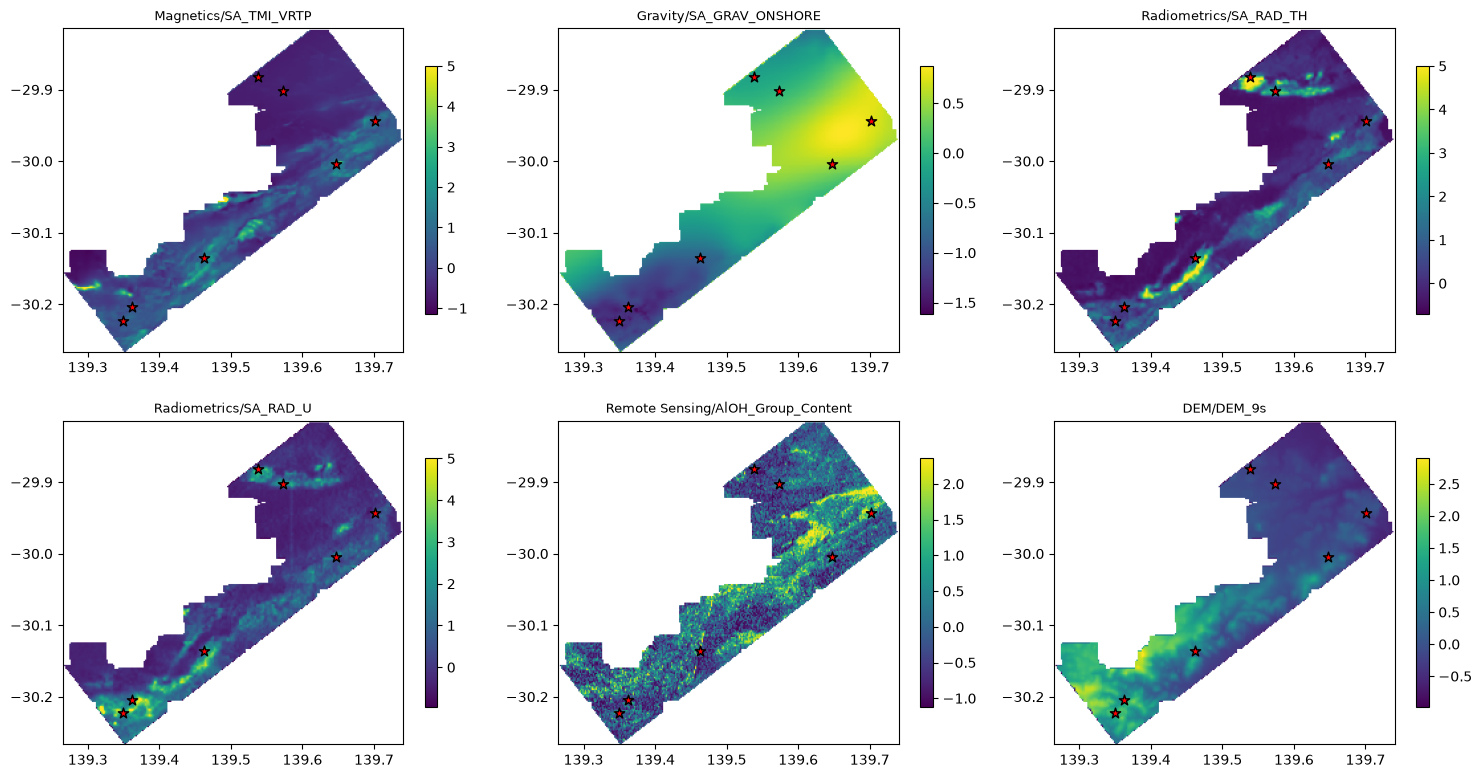

fraction missing (filled with median) per ASTER layer:
{'AlOH_Group_Composition': 0.03, 'AlOH_Group_Content': 0.03, 'FeOH_Group_Content': 0.92, 'Ferric_Oxide_Composition': 0.02, 'Ferric_Oxide_Content': 0.03, 'Ferrous_Iron_Content_in_MgOH': 0.88, 'Ferrous_Iron_Index': 0.08, 'Green_Vegetation': 0.6, 'Gypsum_Index': 0.87, 'Kaolin_Group_Index': 0.95, 'MgOH_Group_Composition': 0.88, 'MgOH_Group_Content': 0.85, 'Opaque_Index': 0.6, 'Quartz_Index': 0.04, 'Silica_Index': 0.01}


In [3]:
names = ["Magnetics/SA_TMI_VRTP", "Gravity/SA_GRAV_ONSHORE", "Radiometrics/SA_RAD_TH", "Radiometrics/SA_RAD_U", "Remote Sensing/AlOH_Group_Content", "DEM/DEM_9s"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, n in zip(axes.flat, names):
    show(ax, gg.stack[gg.channel_names.index(n)], n)
plt.tight_layout(); plt.show()
print("fraction missing (filled with median) per ASTER layer:")
print({k.split('/')[-1]: round(v, 2) for k, v in gg.meta["nan_fraction"].items() if k.startswith("Remote")})

## Spatial prior w: power-law fits

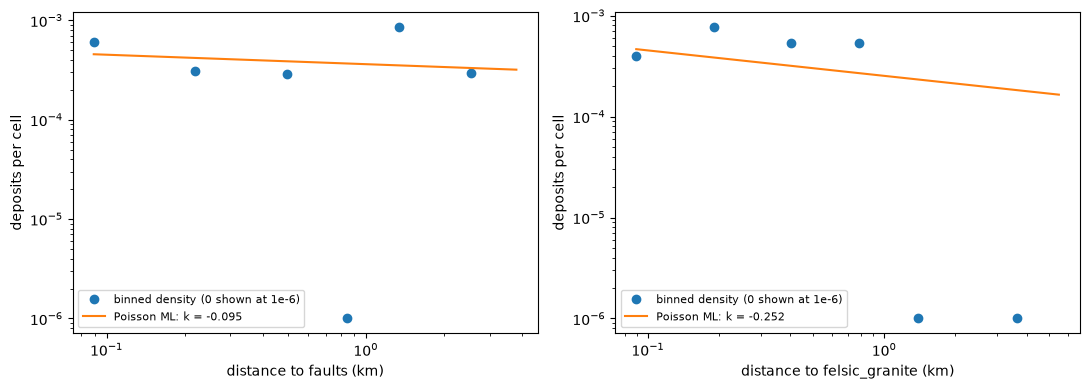

In [4]:
pc = PriorConfig()
w_map, fits = build_spatial_prior(gg.distances, gg.deposits_rc, gg.valid, pc.n_bins, pc.combine, pc.drop_nonnegative_k)
fig, axes = plt.subplots(1, len(fits), figsize=(11, 4))
for ax, (name, fit) in zip(axes, fits.items()):
    ax.loglog(fit.bin_centers, np.maximum(fit.density, 1e-6), "o", label="binned density (0 shown at 1e-6)")
    dd = np.geomspace(fit.d_min, fit.bin_centers.max() * 1.5, 50)
    ax.loglog(dd, fit.N * dd ** fit.k, "-", label=f"Poisson ML: k = {fit.k:.3f}")
    ax.set_xlabel(f"distance to {name} (km)"); ax.set_ylabel("deposits per cell"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

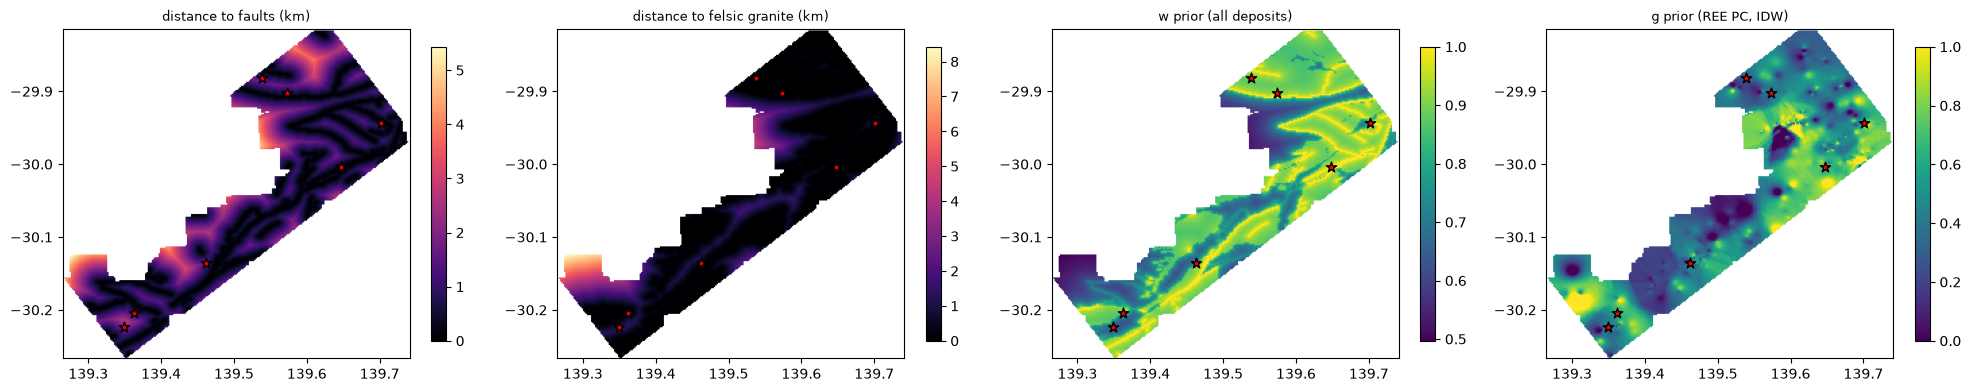

deposit area ranks (fraction of map scoring >= deposit; random ≈ 0.5)
  w: [0.4  0.06 0.38 0.86 0.57 0.71 0.19]
  g: [0.79 0.2  0.34 0.65 0.2  0.83 0.7 ]
g loadings: {'Ag': -0.146, 'As': -0.179, 'Au': -0.23, 'BaO': 0.114, 'Bi': -0.156, 'Co': -0.167, 'Cr2O3': -0.141, 'Cs': 0.154, 'Cu': -0.197, 'La': 0.222, 'Mo': -0.177, 'Nb': 0.307, 'Ni': -0.188, 'Pb': -0.149, 'Rb': 0.273, 'Sb': -0.214, 'Sc': 0.157, 'Sn': 0.196, 'SrO': -0.134, 'Ta': 0.218, 'Th': 0.295, 'U3O8': 0.128, 'V': -0.137, 'W': 0.18, 'Y': 0.188, 'Zn': -0.102, 'Zr': 0.254}


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
show(axes[0], gg.distances["faults"], "distance to faults (km)", "magma")
show(axes[1], gg.distances["felsic_granite"], "distance to felsic granite (km)", "magma")
show(axes[2], w_map, "w prior (all deposits)")
show(axes[3], gg.g_map, "g prior (REE PC, IDW)")
plt.tight_layout(); plt.show()
print("deposit area ranks (fraction of map scoring >= deposit; random ≈ 0.5)")
print("  w:", area_rank(w_map, gg.valid, gg.deposits_rc).round(2))
print("  g:", area_rank(gg.g_map, gg.valid, gg.deposits_rc).round(2))
print("g loadings:", gg.meta["geochem_pca"]["loadings"])

**Note for the write-up.** Only 7 REE occurrences exist. The fitted decay exponents are weak (|k| < 0.3) and unstable across leave-one-out folds, and neither prior on its own ranks deposits much above random. The hard constraints therefore have limited signal to inject in this area. That makes ablations (with/without w, g) essential, and the dataset well suited to test whether the constraints help or hurt when priors are weak.